In [ ]:
print("welcome to my first EDA project")

welcome to my first EDA project


In [ ]:
import zipfile
import os

with zipfile.ZipFile('/content/dataset.csv.zip', 'r') as zip_ref:
    zip_ref.extractall('/content/spotify_data')

print("Dataset extracted successfully!")
print(os.listdir('/content/spotify_data'))

Dataset extracted successfully!
['dataset.csv']


In [ ]:
import pandas as pd

df = pd.read_csv('/content/spotify_data/dataset.csv')

print("Dataset loaded successfully!")

Dataset loaded successfully!


In [ ]:
# display the first 5 rows
df.head()

,Unnamed: 0,track_id,artists,album_name,track_name,popularity,duration_ms,explicit,danceability,energy,...,loudness,mode,speechiness,acousticness,instrumentalness,liveness,valence,tempo,time_signature,track_genre
0,0,5SuOikwiRyPMVoIQDJUgSV,Gen Hoshino,Comedy,Comedy,73,230666,False,0.676,0.4610,...,-6.746,0,0.1430,0.0322,0.000001,0.3580,0.715,87.917,4,acoustic
1,1,4qPNDBW1i3p13qLCt0Ki3A,Ben Woodward,Ghost (Acoustic),Ghost - Acoustic,55,149610,False,0.420,0.1660,...,-17.235,1,0.0763,0.9240,0.000006,0.1010,0.267,77.489,4,acoustic
2,2,1iJBSr7s7jYXzM8EGcbK5b,Ingrid Michaelson;ZAYN,To Begin Again,To Begin Again,57,210826,False,0.438,0.3590,...,-9.734,1,0.0557,0.2100,0.000000,0.1170,0.120,76.332,4,acoustic
3,3,6lfxq3CG4xtTiEg7opyCyx,Kina Grannis,Crazy Rich Asians (Original Motion Picture Sou...,Can't Help Falling In Love,71,201933,False,0.266,0.0596,...,-18.515,1,0.0363,0.9050,0.000071,0.1320,0.143,181.740,3,acoustic
4,4,5vjLSffimiIP26QG5WcN2K,Chord Overstreet,Hold On,Hold On,82,198853,False,0.618,0.4430,...,-9.681,1,0.0526,0.4690,0.000000,0.0829,0.167,119.949,4,acoustic


In [ ]:
print("dataset shape: ", df.shape)
print("number of songs: ", df.shape[0])
print("number of columns: ", df.shape[1])

dataset shape:  (114000, 21)
number of songs:  114000
number of columns:  21


In [ ]:
print("column name in the spotify dataset: \n")
for column in df.columns:
  print(column)


column name in the spotify dataset: 

Unnamed: 0
track_id
artists
album_name
track_name
popularity
duration_ms
explicit
danceability
energy
key
loudness
mode
speechiness
acousticness
instrumentalness
liveness
valence
tempo
time_signature
track_genre


In [ ]:
print("Missing values in each column: ")
print(df.isnull().sum())

Missing values in each column: 
Unnamed: 0          0
track_id            0
artists             1
album_name          1
track_name          1
popularity          0
duration_ms         0
explicit            0
danceability        0
energy              0
key                 0
loudness            0
mode                0
speechiness         0
acousticness        0
instrumentalness    0
liveness            0
valence             0
tempo               0
time_signature      0
track_genre         0
dtype: int64


In [ ]:
print("Number of duplicate rows: ")
df.duplicated().sum()

Number of duplicate rows: 


np.int64(0)

In [ ]:
print("Number of unique genres: ")
print(df["track_genre"].nunique())

print("\nFirst 20 genres: ")
print(df["track_genre"].unique()[:20])

Number of unique genres: 
114

First 20 genres: 
['acoustic' 'afrobeat' 'alt-rock' 'alternative' 'ambient' 'anime'
 'black-metal' 'bluegrass' 'blues' 'brazil' 'breakbeat' 'british'
 'cantopop' 'chicago-house' 'children' 'chill' 'classical' 'club' 'comedy'
 'country']


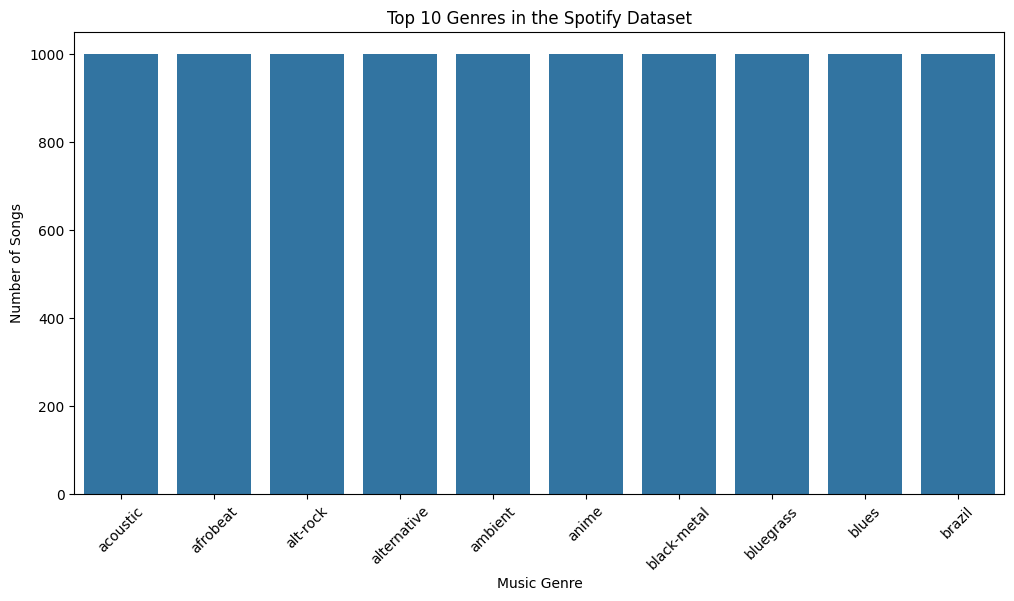

In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns

genre_counts = df["track_genre"].value_counts().head(10)

plt.figure(figsize=(12, 6))

sns.barplot(
    x=genre_counts.index,
    y=genre_counts.values
)

plt.title("Top 10 Genres in the Spotify Dataset")
plt.xlabel("Music Genre")
plt.ylabel("Number of Songs")
plt.xticks(rotation=45)
plt.show()

In [ ]:
print("Popularity statistics:")
print(df["popularity"].describe())

Popularity statistics:
count    114000.000000
mean         33.238535
std          22.305078
min           0.000000
25%          17.000000
50%          35.000000
75%          50.000000
max         100.000000
Name: popularity, dtype: float64


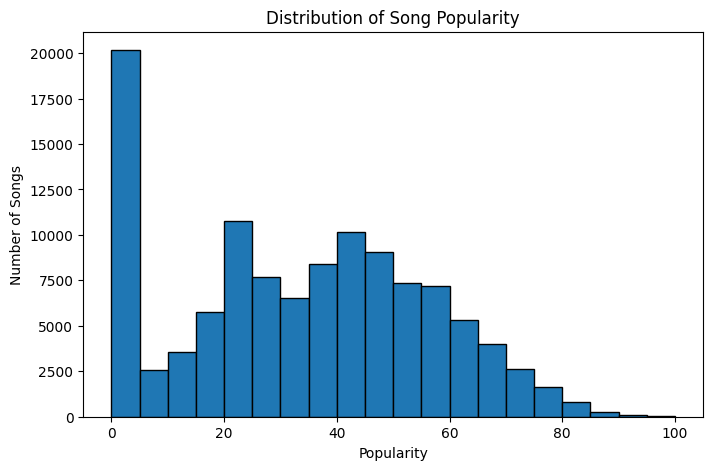

In [ ]:
 import matplotlib.pyplot as plt

plt.figure(figsize=(8, 5))
plt.hist(df["popularity"], bins=20, edgecolor="black")
plt.title("Distribution of Song Popularity")
plt.xlabel("Popularity")
plt.ylabel("Number of Songs")
plt.show()

In [ ]:
top_10_songs = df.nlargest(
    10, "popularity"
)[["track_name", "artists", "track_genre", "popularity"]]

print(top_10_songs.to_string(index=False))

                           track_name                 artists track_genre  popularity
            Unholy (feat. Kim Petras)    Sam Smith;Kim Petras       dance         100
            Unholy (feat. Kim Petras)    Sam Smith;Kim Petras         pop         100
Quevedo: Bzrp Music Sessions, Vol. 52        Bizarrap;Quevedo     hip-hop          99
                      I'm Good (Blue) David Guetta;Bebe Rexha       dance          98
                      I'm Good (Blue) David Guetta;Bebe Rexha         edm          98
                           La Bachata           Manuel Turizo       latin          98
                           La Bachata           Manuel Turizo      latino          98
                      I'm Good (Blue) David Guetta;Bebe Rexha         pop          98
                           La Bachata           Manuel Turizo      reggae          98
                           La Bachata           Manuel Turizo   reggaeton          98


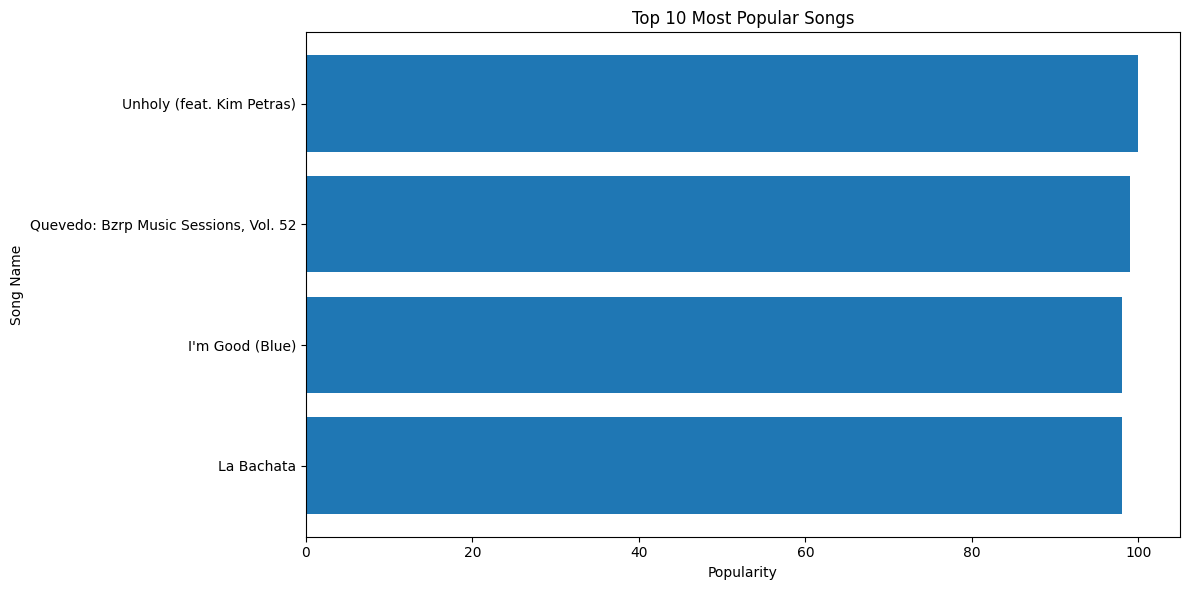

In [ ]:
import matplotlib.pyplot as plt

plt.figure(figsize=(12, 6))
plt.barh(
    top_10_songs["track_name"],
    top_10_songs["popularity"]
)
plt.xlabel("Popularity")
plt.ylabel("Song Name")
plt.title("Top 10 Most Popular Songs")
plt.gca().invert_yaxis()
plt.tight_layout()
plt.show()

In [ ]:
genre_popularity = (
    df.groupby("track_genre")["popularity"]
    .mean()
    .sort_values(ascending=False)
)

print("Top 10 genres by average popularity:")
print(genre_popularity.head(10))

Top 10 genres by average popularity:
track_genre
pop-film     59.283
k-pop        56.896
chill        53.651
sad          52.379
grunge       49.594
indian       49.539
anime        48.772
emo          48.128
sertanejo    47.866
pop          47.576
Name: popularity, dtype: float64


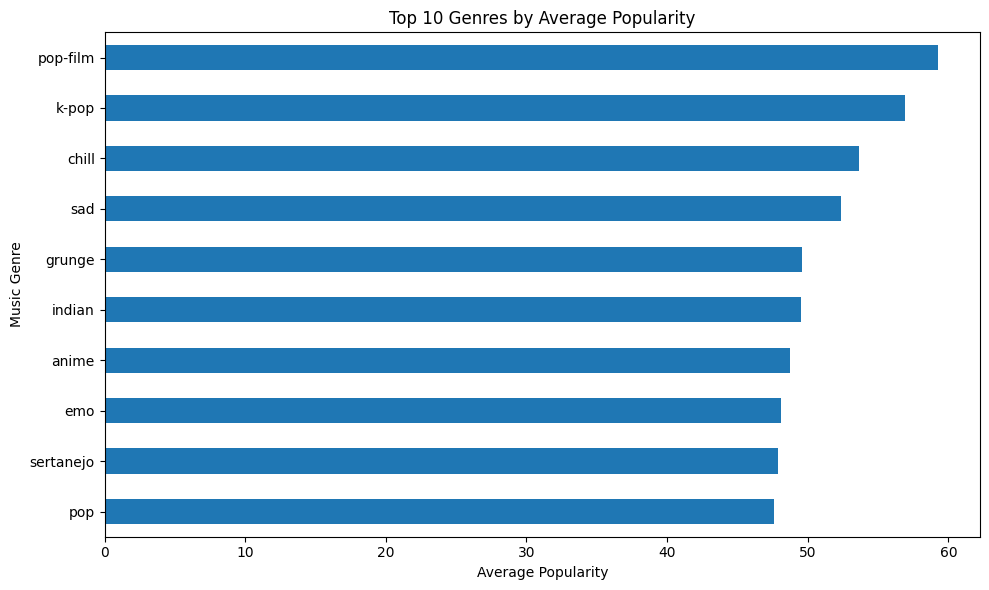

In [ ]:
import matplotlib.pyplot as plt

top_10_genres = genre_popularity.head(10).sort_values()

plt.figure(figsize=(10, 6))
top_10_genres.plot(kind="barh")
plt.title("Top 10 Genres by Average Popularity")
plt.xlabel("Average Popularity")
plt.ylabel("Music Genre")
plt.tight_layout()
plt.show()

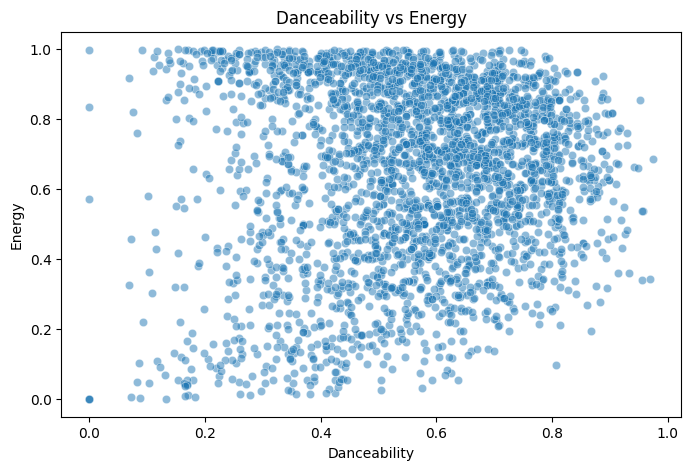

In [ ]:
plt.figure(figsize=(8, 5))

sns.scatterplot(
    data=df.sample(min(3000, len(df)), random_state=42),
    x="danceability",
    y="energy",
    alpha=0.5
)

plt.title("Danceability vs Energy")
plt.xlabel("Danceability")
plt.ylabel("Energy")
plt.show()

In [ ]:
correlation = df["danceability"].corr(df["energy"])

print("Correlation:", round(correlation, 3))

Correlation: 0.134


In [ ]:
correlation = df["energy"].corr(df["loudness"])
print("Correlation between energy and loudness:", round(correlation, 3))

Correlation between energy and loudness: 0.762


In [ ]:
print(df.isnull().sum())

Unnamed: 0          0
track_id            0
artists             1
album_name          1
track_name          1
popularity          0
duration_ms         0
explicit            0
danceability        0
energy              0
key                 0
loudness            0
mode                0
speechiness         0
acousticness        0
instrumentalness    0
liveness            0
valence             0
tempo               0
time_signature      0
track_genre         0
dtype: int64


In [ ]:
df = df.dropna(subset=["artists", "album_name", "track_name"])

print("Dataset shape after cleaning:", df.shape)

Dataset shape after cleaning: (113999, 21)


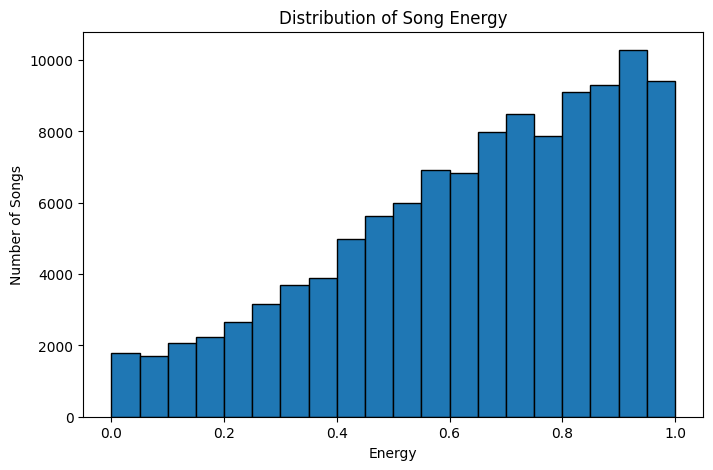

In [ ]:
import matplotlib.pyplot as plt

plt.figure(figsize=(8, 5))

plt.hist(df["energy"], bins=20, edgecolor="black")

plt.title("Distribution of Song Energy")
plt.xlabel("Energy")
plt.ylabel("Number of Songs")

plt.show()

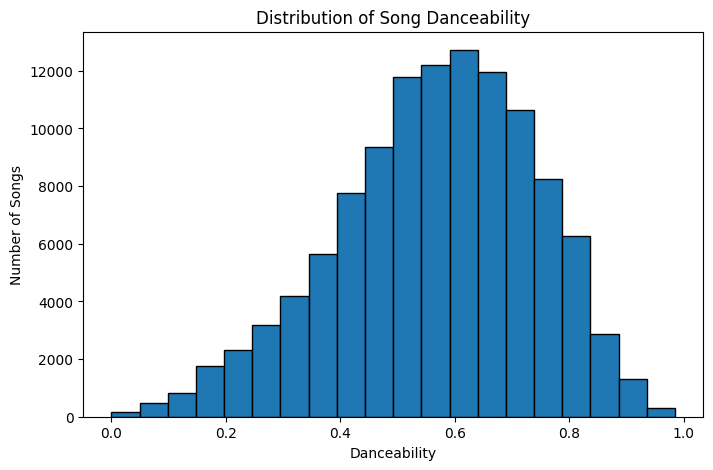

In [ ]:
plt.figure(figsize=(8, 5))

plt.hist(df["danceability"], bins=20, edgecolor="black")

plt.title("Distribution of Song Danceability")
plt.xlabel("Danceability")
plt.ylabel("Number of Songs")

plt.show()

In [ ]:
top_10_songs = df.nlargest(10, "popularity")[
    ["track_name", "artists", "track_genre", "popularity"]
]

print(top_10_songs.to_string(index=False))

                           track_name                 artists track_genre  popularity
            Unholy (feat. Kim Petras)    Sam Smith;Kim Petras       dance         100
            Unholy (feat. Kim Petras)    Sam Smith;Kim Petras         pop         100
Quevedo: Bzrp Music Sessions, Vol. 52        Bizarrap;Quevedo     hip-hop          99
                      I'm Good (Blue) David Guetta;Bebe Rexha       dance          98
                      I'm Good (Blue) David Guetta;Bebe Rexha         edm          98
                           La Bachata           Manuel Turizo       latin          98
                           La Bachata           Manuel Turizo      latino          98
                      I'm Good (Blue) David Guetta;Bebe Rexha         pop          98
                           La Bachata           Manuel Turizo      reggae          98
                           La Bachata           Manuel Turizo   reggaeton          98


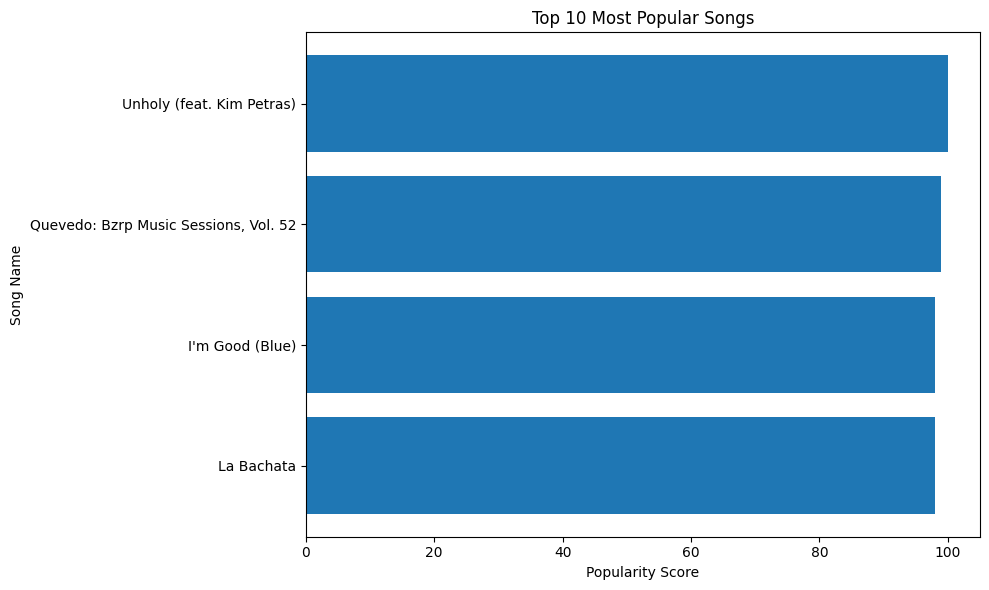

In [ ]:
import matplotlib.pyplot as plt

plt.figure(figsize=(10, 6))

plt.barh(
    top_10_songs["track_name"],
    top_10_songs["popularity"]
)

plt.xlabel("Popularity Score")
plt.ylabel("Song Name")
plt.title("Top 10 Most Popular Songs")

plt.gca().invert_yaxis()
plt.tight_layout()
plt.show()

In [ ]:
genre_popularity = (
    df.groupby("track_genre")["popularity"]
    .mean()
    .sort_values(ascending=False)
)

print("Top 10 genres by average popularity:")
print(genre_popularity.head(10))

Top 10 genres by average popularity:
track_genre
pop-film     59.283000
k-pop        56.952953
chill        53.651000
sad          52.379000
grunge       49.594000
indian       49.539000
anime        48.772000
emo          48.128000
sertanejo    47.866000
pop          47.576000
Name: popularity, dtype: float64


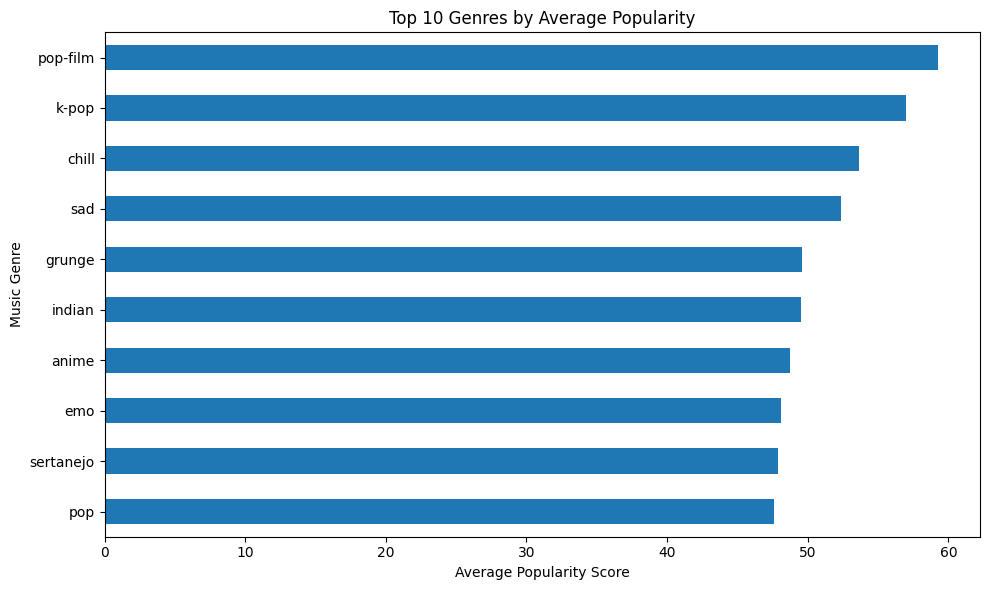

In [ ]:
top_10_genres = genre_popularity.head(10).sort_values()

plt.figure(figsize=(10, 6))

top_10_genres.plot(kind="barh")

plt.title("Top 10 Genres by Average Popularity")
plt.xlabel("Average Popularity Score")
plt.ylabel("Music Genre")

plt.tight_layout()
plt.show()

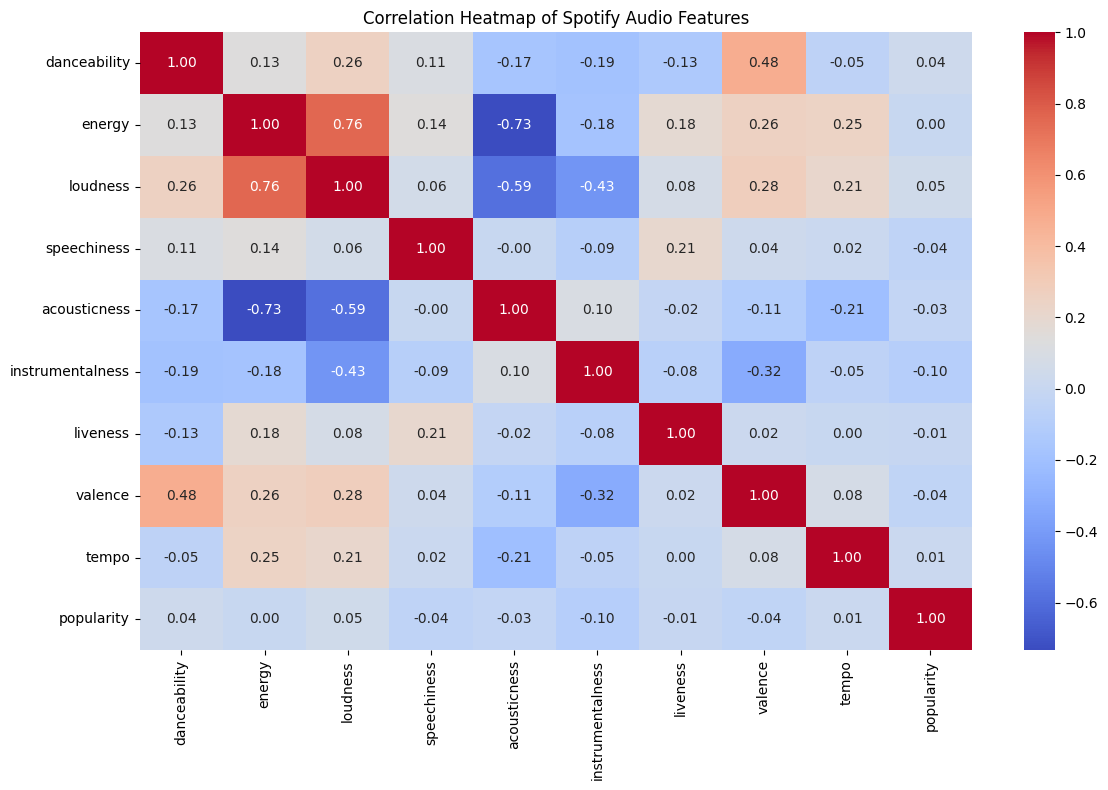

In [ ]:
import seaborn as sns
import matplotlib.pyplot as plt

audio_features = [
    "danceability",
    "energy",
    "loudness",
    "speechiness",
    "acousticness",
    "instrumentalness",
    "liveness",
    "valence",
    "tempo",
    "popularity"
]

correlation_matrix = df[audio_features].corr()

plt.figure(figsize=(12, 8))

sns.heatmap(
    correlation_matrix,
    annot=True,
    cmap="coolwarm",
    fmt=".2f"
)

plt.title("Correlation Heatmap of Spotify Audio Features")
plt.tight_layout()
plt.show()

In [ ]:
print("Duplicate rows: ", df.duplicated().sum())

Duplicate rows:  0


In [ ]:
print("SPOTIFY DATASET SUMMARY")
print("-----------------------")

print("Total songs:", df.shape[0])
print("Total columns:", df.shape[1])
print("Number of genres:", df["track_genre"].nunique())
print("Missing values:", df.isnull().sum().sum())
print("Duplicate rows:", df.duplicated().sum())

print("\nAverage popularity:", round(df["popularity"].mean(), 2))
print("Average danceability:", round(df["danceability"].mean(), 2))
print("Average energy:", round(df["energy"].mean(), 2))

SPOTIFY DATASET SUMMARY
-----------------------
Total songs: 113999
Total columns: 21
Number of genres: 114
Missing values: 0
Duplicate rows: 0

Average popularity: 33.24
Average danceability: 0.57
Average energy: 0.64


In [ ]:
print(df.columns.tolist())

['Unnamed: 0', 'track_id', 'artists', 'album_name', 'track_name', 'popularity', 'duration_ms', 'explicit', 'danceability', 'energy', 'key', 'loudness', 'mode', 'speechiness', 'acousticness', 'instrumentalness', 'liveness', 'valence', 'tempo', 'time_signature', 'track_genre']


In [ ]:
features = [
    "danceability",
    "energy",
    "loudness",
    "speechiness",
    "acousticness",
    "instrumentalness",
    "liveness",
    "valence",
    "tempo"
]

music_features = df[features]

print(music_features.head())

   danceability  energy  loudness  speechiness  acousticness  \
0         0.676  0.4610    -6.746       0.1430        0.0322   
1         0.420  0.1660   -17.235       0.0763        0.9240   
2         0.438  0.3590    -9.734       0.0557        0.2100   
3         0.266  0.0596   -18.515       0.0363        0.9050   
4         0.618  0.4430    -9.681       0.0526        0.4690   

   instrumentalness  liveness  valence    tempo  
0          0.000001    0.3580    0.715   87.917  
1          0.000006    0.1010    0.267   77.489  
2          0.000000    0.1170    0.120   76.332  
3          0.000071    0.1320    0.143  181.740  
4          0.000000    0.0829    0.167  119.949  


In [ ]:
from sklearn.preprocessing import StandardScaler

scaler = StandardScaler()

scaled_features = scaler.fit_transform(music_features)

print("Original features shape:", music_features.shape)
print("Scaled features shape:", scaled_features.shape)

Original features shape: (113999, 9)
Scaled features shape: (113999, 9)


In [3]:
print("df exists:", "df" in globals())
print("music_features exists:", "music_features" in globals())
print("scaled_features exists:", "scaled_features" in globals())

df exists: False
music_features exists: False
scaled_features exists: False


In [4]:
import pandas as pd

df = pd.read_csv('/content/spotify_data/dataset.csv')

df = df.dropna(
    subset=["artists", "album_name", "track_name"]
)

print("Dataset loaded successfully!")
print("Dataset shape:", df.shape)

Dataset loaded successfully!
Dataset shape: (113999, 21)


In [5]:
features = [
    "danceability",
    "energy",
    "loudness",
    "speechiness",
    "acousticness",
    "instrumentalness",
    "liveness",
    "valence",
    "tempo"
]

music_features = df[features]

print("Audio features prepared!")
print("Shape:", music_features.shape)

Audio features prepared!
Shape: (113999, 9)


In [6]:
from sklearn.preprocessing import StandardScaler

scaler = StandardScaler()
scaled_features = scaler.fit_transform(music_features)

print("Scaled features shape:", scaled_features.shape)

Scaled features shape: (113999, 9)


In [8]:
from sklearn.metrics.pairwise import cosine_similarity
import numpy as np

def recommend_songs(song_name, n=5):
    matches = df[
        df["track_name"].str.contains(
            song_name, case=False, na=False, regex=False
        )
    ]

    if matches.empty:
        print("Song not found. Try another song name.")
        return

    song_index = matches.index[0]

    scores = cosine_similarity(
        scaled_features[song_index].reshape(1, -1),
        scaled_features
    )[0]

    scores[song_index] = -1

    top_indices = np.argsort(scores)[::-1]
    top_indices = [
        i for i in top_indices
        if df.index[i] != song_index
    ][:n]

    print("Recommendations for:", df.loc[song_index, "track_name"])
    print(
        df.iloc[top_indices][
            ["track_name", "artists", "track_genre", "popularity"]
        ].to_string(index=False)
    )

In [9]:
recommend_songs("shape of you")

Recommendations for: Shape Of You
                                          track_name                                                  artists track_genre  popularity
                                           Reno Ride                                           Clarence White   bluegrass          24
                                         Always Will                        Steve Martin;Steep Canyon Rangers   bluegrass          22
                                   Minuet in F, K.1d                       Wolfgang Amadeus Mozart;Erik Smith   classical           3
                                   Minuet in F, K.1d                       Wolfgang Amadeus Mozart;Erik Smith   classical           3
Les Indes Galantes - Air pour les esclaves africains Jean-Philippe Rameau;Jordi Savall;Le Concert Des Nations       opera          21


In [12]:
song = input("enter a song name: ")
recommend_songs(song)


enter a song name: the box
Recommendations for: Man in the Box
    track_name          artists track_genre  popularity
Man in the Box  Alice In Chains       metal          75
Man in the Box  Alice In Chains   hard-rock          75
Man in the Box  Alice In Chains      grunge          75
     What's Up Lack Of Interest   grindcore          12
   Black Roses   Sloppy Seconds   power-pop          22


In [13]:
from sklearn.metrics.pairwise import cosine_similarity
import numpy as np

def recommend_songs(song_name, n=5):
    matches = df[
        df["track_name"].str.contains(
            song_name, case=False, na=False, regex=False
        )
    ]

    if matches.empty:
        print("Song not found. Try another song name.")
        return

    song_index = matches.index[0]

    scores = cosine_similarity(
        scaled_features[song_index].reshape(1, -1),
        scaled_features
    )[0]

    scores[song_index] = -1

    top_indices = np.argsort(scores)[::-1][:n]

    recommendations = df.iloc[top_indices][
        ["track_name", "artists", "track_genre", "popularity"]
    ]

    return recommendations.reset_index(drop=True)

In [14]:
song = input("enter a song name: ")
recommend_songs(song)


enter a song name: baby


,track_name,artists,track_genre,popularity
0,ily (i love you baby),Andrew Foy;Renee Foy,guitar,56
1,Galleries of Pink Galahs,John Williamson,children,32
2,Sweet Annie,Twinkle Twinkle Little Rock Star,children,28
3,Unicorn and the Sheep,Raghav Meattle,songwriter,32
4,Unicorn and the Sheep,Raghav Meattle,singer-songwriter,32


In [15]:
from sklearn.metrics.pairwise import cosine_similarity
import numpy as np
import pandas as pd

def recommend_songs(song_name, n=5):
    matches = df[
        df["track_name"].str.contains(
            song_name, case=False, na=False, regex=False
        )
    ]

    if matches.empty:
        print("Song not found. Try another song name.")
        return

    song_index = df.index.get_loc(matches.index[0])

    scores = cosine_similarity(
        scaled_features[song_index].reshape(1, -1),
        scaled_features
    )[0]

    scores[song_index] = -1
    top_indices = np.argsort(scores)[::-1][:n]

    recommendations = df.iloc[top_indices][
        ["track_name", "artists", "track_genre", "popularity"]
    ].copy()

    recommendations["similarity_score"] = (
        scores[top_indices].round(3)
    )

    return recommendations.reset_index(drop=True)

In [16]:
recommend_songs("shape of you")

,track_name,artists,track_genre,popularity,similarity_score
0,Reno Ride,Clarence White,bluegrass,24,0.980
1,Always Will,Steve Martin;Steep Canyon Rangers,bluegrass,22,0.980
2,"Minuet in F, K.1d",Wolfgang Amadeus Mozart;Erik Smith,classical,3,0.980
3,"Minuet in F, K.1d",Wolfgang Amadeus Mozart;Erik Smith,classical,3,0.980
4,Les Indes Galantes - Air pour les esclaves afr...,Jean-Philippe Rameau;Jordi Savall;Le Concert D...,opera,21,0.978


In [17]:
print("end of my project")

end of my project
